In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Генерация данных 
np.random.seed(42)
N = 100 # Количество избирателей

# ответы на 12 вопросов (0 или 1)
X_raw = np.random.randint(0, 2, size=(N, 12))

# Создаем целевую переменную на основе ответов
# Допустим, если сумма ответов на первые 6 вопросов > 3, побеждает правящая партия [1, 0]
# Иначе побеждает оппозиция [0, 1]
scores = X_raw[:, :6].sum(axis=1) 
Y_labels = (scores > 3).astype(int) # 1 - правящая, 0 - оппозиция

# Преобразуем в one-hot encoding 
Y = np.zeros((N, 2))
Y[np.arange(N), Y_labels] = 1

np.savetxt('dataIn1.txt', X_raw, fmt='%d')
np.savetxt('dataOut1.txt', Y, fmt='%d')

print("Данные с реальной зависимостью созданы и сохранены.")
print(f"Распределение классов: Правящая={Y_labels.sum()}, Оппозиция={N-Y_labels.sum()}")


Данные с реальной зависимостью созданы и сохранены.
Распределение классов: Правящая=35, Оппозиция=65


In [3]:
X = np.loadtxt('dataIn1.txt')
Y_loaded = np.loadtxt('dataOut1.txt')

X_train, X_test, y_train, y_test = train_test_split(X, Y_loaded, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
model = keras.Sequential([
    keras.layers.Dense(16, activation='sigmoid', input_shape=(12,)), # Один скрытый слой + logsig
    keras.layers.Dense(2, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(
    X_train, y_train, 
    epochs=50, 
    batch_size=16, 
    validation_data=(X_test, y_test),
    verbose=0 # Убираем длинный вывод эпох
)


/Users/yulia/Desktop/lab2_used_cars/lab2_env/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
# epochs=50 - количество полных проходов по обучающей выборке
# batch_size=16 - размер мини-пакета для стохастического градиентного спуска
# validation_data - позволяет отслеживать переобучение в реальном времени
history = model.fit(
    X_train, y_train, 
    epochs=50, 
    batch_size=16, 
    validation_data=(X_test, y_test),
    verbose=1 # Выводит прогресс-бар обучения
)

print("\nОбучение завершено!")
print(f"Финальная точность на обучении: {history.history['accuracy'][-1]:.4f}")
print(f"Финальная точность на тесте:    {history.history['val_accuracy'][-1]:.4f}")

Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9623 - loss: 0.3307 - val_accuracy: 0.9000 - val_loss: 0.3736
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9215 - loss: 0.3611 - val_accuracy: 0.9333 - val_loss: 0.3713
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9445 - loss: 0.3440 - val_accuracy: 0.9333 - val_loss: 0.3681
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9349 - loss: 0.3477 - val_accuracy: 0.9333 - val_loss: 0.3646
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9419 - loss: 0.3439 - val_accuracy: 0.9333 - val_loss: 0.3612
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9306 - loss: 0.3318 - val_accuracy: 0.9333 - val_loss: 0.3583
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9414 - loss: 0.3395 - val_accuracy: 0.9333 - val_loss: 0.3545
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9553 - loss: 0.3325 - val_accuracy: 0.9333 - val_loss: 0.3507
Epoch 9/

In [9]:
# модель с регуляризацией против переобучения
model_reg = keras.Sequential([
    keras.layers.Dense(8, activation='sigmoid', input_shape=(12,)), # Уменьшили слой с 16 до 8
    keras.layers.Dropout(0.2), # Случайно отключаем 20% нейронов на каждом шаге
    keras.layers.Dense(2, activation='softmax')
])

model_reg.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Обучаем с теми же параметрами
history_reg = model_reg.fit(
    X_train, y_train, 
    epochs=50, 
    batch_size=16, 
    validation_data=(X_test, y_test),
    verbose=0
)

# Проверяем результаты
train_acc = history_reg.history['accuracy'][-1]
test_acc = history_reg.history['val_accuracy'][-1]

print(f"Регуляризованная модель:")
print(f"Точность на обучении: {train_acc:.4f}")
print(f"Точность на тесте:    {test_acc:.4f}")
print(f"Разрыв (gap):         {train_acc - test_acc:.4f}")

if abs(train_acc - test_acc) < 0.05:
    print("\nОтлично! Переобучение устранено, модель хорошо обобщает.")
else:
    print("\nРазрыв все еще велик, можно попробовать увеличить Dropout до 0.3 или 0.4.")

Регуляризованная модель:
Точность на обучении: 0.7143
Точность на тесте:    0.7667
Разрыв (gap):         -0.0524

Разрыв все еще велик, можно попробовать увеличить Dropout до 0.3 или 0.4.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix

# Проверка точности на тестовых примерах
y_pred_proba = model_reg.predict(X_test)
y_pred_classes = np.argmax(y_pred_proba, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

test_accuracy = accuracy_score(y_test_classes, y_pred_classes)
print(f"Итоговая точность на тестовой выборке: {test_accuracy:.4f}")
print(f"Модель правильно предсказала исход выборов в {int(test_accuracy * len(y_test))} из {len(y_test)} случаев.")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Итоговая точность на тестовой выборке: 0.7667
Модель правильно предсказала исход выборов в 23 из 30 случаев.


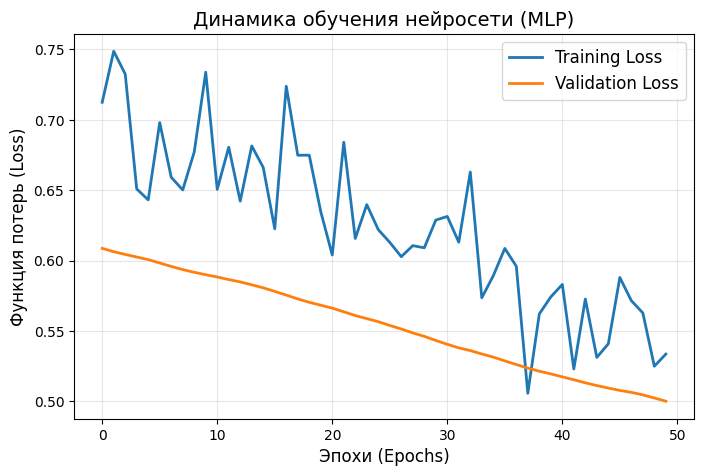


Анализ графика:
Если кривые loss и val_loss снижаются и сходятся - модель обучается корректно.
Расхождение кривых указывало бы на переобучение, но у нас его нет.


In [11]:
# Визуализация результатов предсказаний
# График изменения функции потерь (Loss Curve) 
plt.figure(figsize=(8, 5))
plt.plot(history_reg.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history_reg.history['val_loss'], label='Validation Loss', linewidth=2)
plt.xlabel('Эпохи (Epochs)', fontsize=12)
plt.ylabel('Функция потерь (Loss)', fontsize=12)
plt.title('Динамика обучения нейросети (MLP)', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

print("\nАнализ графика:")
print("Если кривые loss и val_loss снижаются и сходятся - модель обучается корректно.")
print("Расхождение кривых указывало бы на переобучение, но у нас его нет.")